In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
df_clean = pd.read_csv("online_retail_day1_cleaned.csv")
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])
df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)

# Calculate reference date
reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

# Create RFM table
rfm = df_clean.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalAmount": "sum"
})

rfm.rename(columns={
    "InvoiceDate": "Recency",
    "InvoiceNo": "Frequency",
    "TotalAmount": "Monetary"
}, inplace=True)

# Restore cluster numbers and segment names
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

rfm_log = np.log1p(rfm)

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

segment_names = {
    0: "Champions",
    1: "At-Risk Customers",
    2: "Recent Occasional Buyers",
    3: "Regular Customers"
}

rfm["Segment"] = rfm["Cluster"].map(segment_names)

print("RFM data restored successfully!")
print("Shape:", rfm.shape)

RFM data restored successfully!
Shape: (4338, 5)


In [7]:
segment_counts = rfm["Segment"].value_counts()

segment_percentage = (
    rfm["Segment"].value_counts(normalize=True) * 100
).round(2)

segment_analysis = pd.DataFrame({
    "Customer_Count": segment_counts,
    "Percentage": segment_percentage
})

segment_analysis

,Customer_Count,Percentage
Segment,,
At-Risk Customers,1622,37.39
Regular Customers,1166,26.88
Recent Occasional Buyers,837,19.29
Champions,713,16.44


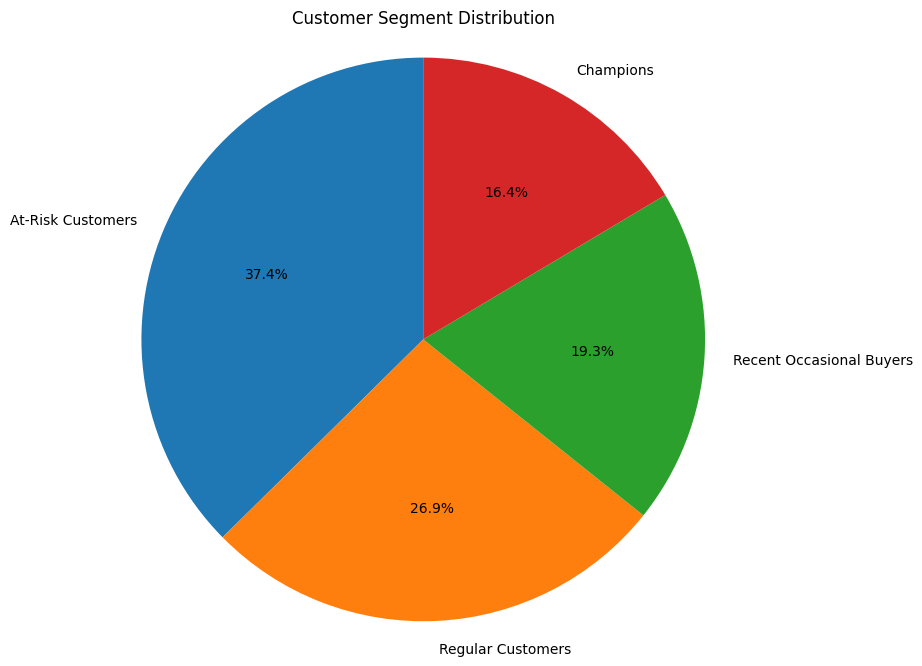

In [8]:
plt.figure(figsize=(8, 8))

plt.pie(
    segment_analysis["Customer_Count"],
    labels=segment_analysis.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Segment Distribution")
plt.axis("equal")
plt.show()

Revenue Contribution by Customer Segment:
Segment
Champions                   5766757.070
Regular Customers           2100873.023
At-Risk Customers            553099.771
Recent Occasional Buyers     466479.030
Name: Monetary, dtype: float64


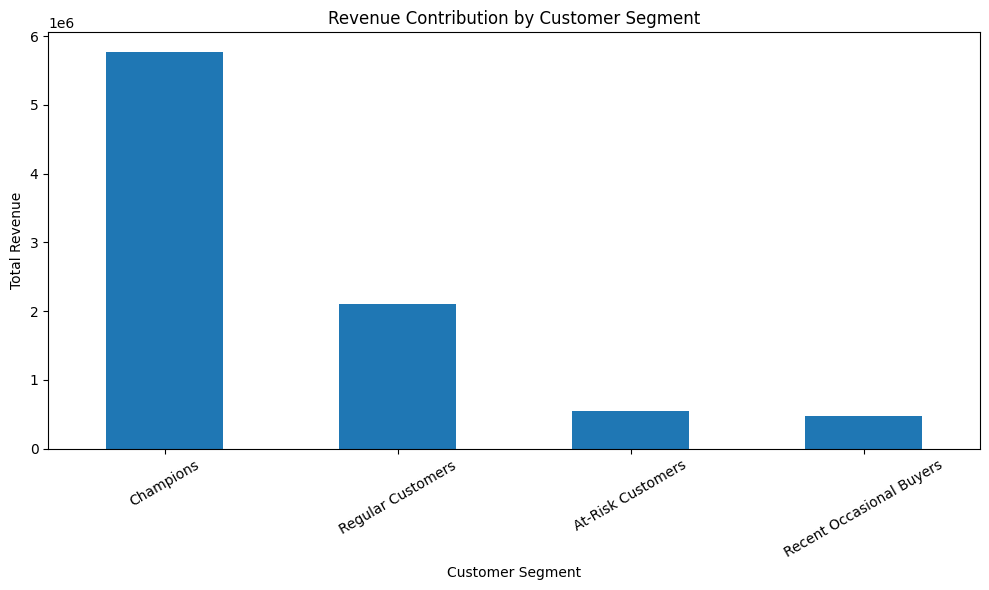

In [9]:
revenue_by_segment = rfm.groupby("Segment")["Monetary"].sum().sort_values(
    ascending=False
)

print("Revenue Contribution by Customer Segment:")
print(revenue_by_segment)

plt.figure(figsize=(10, 6))
revenue_by_segment.plot(kind="bar")

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [10]:
revenue_percentage = (
    revenue_by_segment / revenue_by_segment.sum() * 100
).round(2)

revenue_analysis = pd.DataFrame({
    "Total_Revenue": revenue_by_segment,
    "Revenue_Percentage": revenue_percentage
})

revenue_analysis

,Total_Revenue,Revenue_Percentage
Segment,,
Champions,5766757.070,64.89
Regular Customers,2100873.023,23.64
At-Risk Customers,553099.771,6.22
Recent Occasional Buyers,466479.030,5.25


In [11]:
business_strategies = pd.DataFrame({
    "Customer_Segment": [
        "Champions",
        "Regular Customers",
        "At-Risk Customers",
        "Recent Occasional Buyers"
    ],
    "Business_Strategy": [
        "Loyalty rewards, exclusive offers and early access",
        "Loyalty points and repeat purchase discounts",
        "Win-back campaigns and personalized discounts",
        "Product recommendations and attractive bundles"
    ],
    "Business_Goal": [
        "Retain high-value customers",
        "Increase customer lifetime value",
        "Encourage customers to return",
        "Increase purchase frequency"
    ]
})

business_strategies

,Customer_Segment,Business_Strategy,Business_Goal
0,Champions,"Loyalty rewards, exclusive offers and early ac...",Retain high-value customers
1,Regular Customers,Loyalty points and repeat purchase discounts,Increase customer lifetime value
2,At-Risk Customers,Win-back campaigns and personalized discounts,Encourage customers to return
3,Recent Occasional Buyers,Product recommendations and attractive bundles,Increase purchase frequency


In [12]:
# Save final customer segmentation
rfm.to_csv("final_customer_segmentation.csv")

# Save revenue analysis
revenue_analysis.to_csv("revenue_analysis.csv")

# Save business strategies
business_strategies.to_csv("business_strategies.csv", index=False)

print("All final project files saved successfully!")

print("\nSaved Files:")
print("1. final_customer_segmentation.csv")
print("2. revenue_analysis.csv")
print("3. business_strategies.csv")

All final project files saved successfully!

Saved Files:
1. final_customer_segmentation.csv
2. revenue_analysis.csv
3. business_strategies.csv
